
# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

## Đề tài
Ứng dụng K-Means trong phân nhóm sinh viên dựa trên hành vi học tập nhằm hỗ trợ cá nhân hóa phương pháp học tập.

## 1. Mục tiêu phân tích

- Tìm hiểu cấu trúc và đặc điểm bộ dữ liệu sinh viên.
- Kiểm tra chất lượng dữ liệu sau tiền xử lý.
- Phân tích các đặc trưng liên quan đến hành vi học tập.
- Khám phá sự khác biệt giữa các nhóm sinh viên.
- Đề xuất các đặc trưng phù hợp để xây dựng mô hình K-Means.

## 2. Thông tin dữ liệu

- Nguồn dữ liệu: Kaggle.
- Số bản ghi: 10.000 sinh viên.
- Số thuộc tính ban đầu: 21.
- Số thuộc tính sau tiền xử lý: 19.
- File dữ liệu sử dụng: data/processed/clean_data.csv.


In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Hỗ trợ chạy notebook từ thư mục gốc hoặc notebooks
ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "clean_data.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "clean_data.csv"

df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách thuộc tính:")
print(df.columns.tolist())

display(df.head())


Kích thước dữ liệu: (10000, 19)

Danh sách thuộc tính:
['Mã sinh viên', 'Tên', 'Họ', 'Giới tính', 'Tuổi', 'Ngành học', 'Tỷ lệ chuyên cần (%)', 'Điểm giữa kỳ', 'Điểm cuối kỳ', 'Điểm bài tập trung bình', 'Điểm kiểm tra ngắn trung bình', 'Điểm tham gia học tập', 'Điểm dự án', 'Điểm tổng kết', 'Tham gia khóa ôn tập', 'Điểm Toán', 'Điểm Đọc hiểu', 'Điểm Viết', 'Điểm Khoa học']


,Mã sinh viên,Tên,Họ,Giới tính,Tuổi,Ngành học,Tỷ lệ chuyên cần (%),Điểm giữa kỳ,Điểm cuối kỳ,Điểm bài tập trung bình,Điểm kiểm tra ngắn trung bình,Điểm tham gia học tập,Điểm dự án,Điểm tổng kết,Tham gia khóa ôn tập,Điểm Toán,Điểm Đọc hiểu,Điểm Viết,Điểm Khoa học
0,S1000,Omar,Williams,Female,22.0,Engineering,52.29,55.03,57.82,84.22,74.06,3.99,85.90,56.09,1.0,89,38.0,85.0,26.0
1,S1001,Maria,Brown,Male,18.0,Engineering,97.27,97.23,45.80,74.32,94.24,8.32,55.65,50.64,0.0,65,100.0,67.0,96.0
2,S1002,Ahmed,Jones,Male,24.0,Business,57.19,67.05,93.68,67.70,85.70,5.05,73.79,70.30,0.0,10,99.0,97.0,58.0
3,S1003,Omar,Williams,Female,24.0,Mathematics,95.15,47.79,80.63,66.06,93.51,6.54,92.12,61.63,1.0,22,51.0,41.0,84.0
4,S1004,John,Smith,Female,23.0,CS,54.18,46.59,78.89,96.85,83.70,5.97,68.42,66.13,1.0,26,58.0,64.0,65.0



## 3. Thống kê mô tả dữ liệu

Mục tiêu:
- Xác định số lượng sinh viên và thuộc tính.
- Phân biệt thuộc tính định lượng và định tính.
- Phân tích giá trị trung bình, độ lệch chuẩn, giá trị nhỏ nhất và lớn nhất.
- Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp.


In [20]:

# 3.1. Thông tin tổng quan
print("Số sinh viên:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame(name="Kiểu dữ liệu"))

# 3.2. Thống kê các thuộc tính định lượng
print("\nThống kê mô tả:")

thong_ke = df.describe().T.rename(columns={
    "count": "Số lượng",
    "mean": "Trung bình",
    "std": "Độ lệch chuẩn",
    "min": "Nhỏ nhất",
    "25%": "Q1 (25%)",
    "50%": "Trung vị",
    "75%": "Q3 (75%)",
    "max": "Lớn nhất"
})

display(thong_ke.round(2))

# 3.3. Kiểm tra dữ liệu thiếu
print("\nSố giá trị thiếu theo từng thuộc tính:")
display(
    df.isnull().sum().to_frame(name="Số giá trị thiếu")
)

# 3.4. Kiểm tra dữ liệu trùng lặp
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print(
    "Số mã sinh viên trùng:",
    df["Mã sinh viên"].duplicated().sum()
)


Số sinh viên: 10000
Số thuộc tính: 19

Kiểu dữ liệu:


,Kiểu dữ liệu
Mã sinh viên,str
Tên,str
Họ,str
Giới tính,str
Tuổi,float64
Ngành học,str
Tỷ lệ chuyên cần (%),float64
Điểm giữa kỳ,float64
Điểm cuối kỳ,float64
Điểm bài tập trung bình,float64



Thống kê mô tả:


,Số lượng,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị,Q3 (75%),Lớn nhất
Tuổi,10000.0,20.77,1.87,18.00,19.00,21.00,22.00,24.00
Tỷ lệ chuyên cần (%),10000.0,75.14,14.39,50.01,62.85,75.29,87.41,100.00
Điểm giữa kỳ,10000.0,70.37,17.29,40.00,55.44,70.59,85.24,99.98
Điểm cuối kỳ,10000.0,69.84,17.29,40.00,54.87,69.92,84.84,99.98
Điểm bài tập trung bình,10000.0,74.90,14.37,50.00,62.42,74.85,87.21,99.98
Điểm kiểm tra ngắn trung bình,10000.0,74.84,14.43,50.03,62.36,74.72,87.35,99.96
Điểm tham gia học tập,10000.0,5.01,2.89,0.00,2.49,5.02,7.52,10.00
Điểm dự án,10000.0,75.28,14.43,50.01,62.81,75.40,87.86,100.00
Điểm tổng kết,10000.0,75.03,14.34,50.02,62.84,75.06,87.48,99.99
Tham gia khóa ôn tập,10000.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00



Số giá trị thiếu theo từng thuộc tính:


,Số giá trị thiếu
Mã sinh viên,0
Tên,0
Họ,0
Giới tính,0
Tuổi,0
Ngành học,0
Tỷ lệ chuyên cần (%),0
Điểm giữa kỳ,0
Điểm cuối kỳ,0
Điểm bài tập trung bình,0


Số dòng trùng hoàn toàn: 0
Số mã sinh viên trùng: 0



## 4. Phân tích các thuộc tính định tính

Phân tích cơ cấu sinh viên theo giới tính, ngành học và tình trạng tham gia khóa chuẩn bị kiểm tra.


In [21]:

# 4. Phân tích các thuộc tính định tính

categorical_cols = [
    "Giới tính",
    "Ngành học",
    "Tham gia khóa ôn tập"
]

for col in categorical_cols:
    print(f"\nPhân bố thuộc tính: {col}")

    counts = df[col].value_counts(dropna=False)

    percentages = (
        df[col]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )

    summary = pd.DataFrame({
        "Số lượng": counts,
        "Tỷ lệ (%)": percentages
    })

    display(summary)



Phân bố thuộc tính: Giới tính


,Số lượng,Tỷ lệ (%)
Giới tính,,
Male,5089,50.89
Female,4911,49.11



Phân bố thuộc tính: Ngành học


,Số lượng,Tỷ lệ (%)
Ngành học,,
CS,3975,39.75
Engineering,2986,29.86
Business,2017,20.17
Mathematics,1022,10.22



Phân bố thuộc tính: Tham gia khóa ôn tập


,Số lượng,Tỷ lệ (%)
Tham gia khóa ôn tập,,
0.0,6122,61.22
1.0,3878,38.78



## 5. Nhận xét ban đầu

- Bộ dữ liệu sau tiền xử lý gồm 10.000 bản ghi và 19 thuộc tính.
- Không phát hiện giá trị thiếu hoặc dòng trùng hoàn toàn trong quá trình kiểm tra ban đầu.
- Mã sinh viên được sử dụng để định danh và tra cứu, không sử dụng trực tiếp làm đặc trưng phân cụm.
- Các thuộc tính về chuyên cần, bài tập, kiểm tra và mức độ tham gia học tập là những đặc trưng tiềm năng cho bài toán K-Means.
- Cần tiếp tục phân tích phân phối, ngoại lệ và tương quan giữa các thuộc tính trước khi lựa chọn đặc trưng chính thức.



## 6. Trực quan hóa dữ liệu

### 6.1. Phân bố sinh viên theo giới tính và ngành học

Mục tiêu:
- Xác định cơ cấu giới tính của sinh viên.
- So sánh số lượng sinh viên giữa các ngành học.
- Quan sát sự cân bằng trong phân bố dữ liệu.


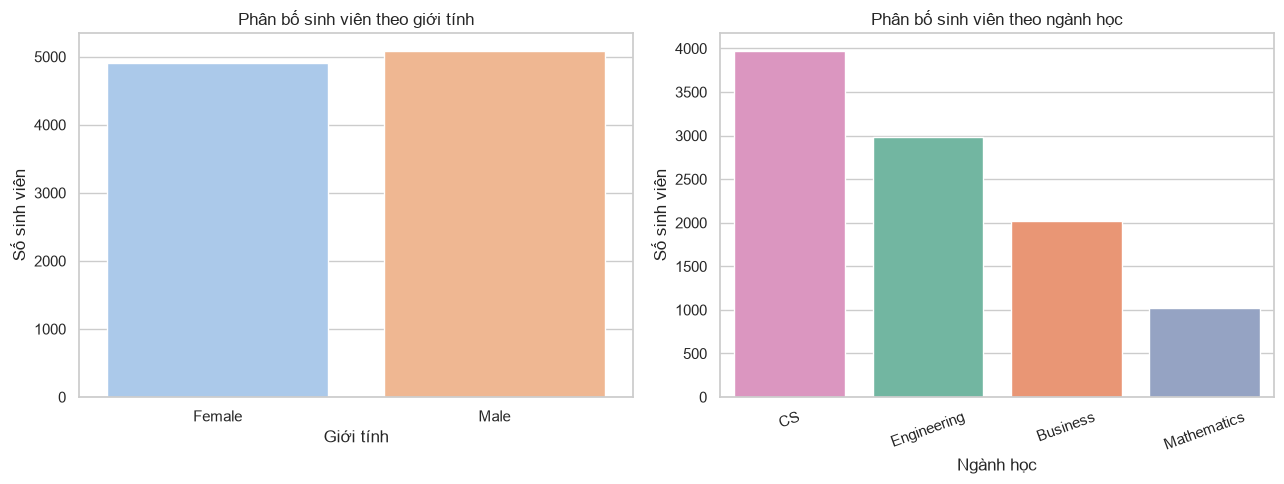

In [22]:

# 6.1. Phân bố sinh viên theo giới tính và ngành học

# Thiết lập font hỗ trợ tiếng Việt
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ giới tính
sns.countplot(
    data=df,
    x="Giới tính",
    hue="Giới tính",
    palette="pastel",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Phân bố sinh viên theo giới tính")
axes[0].set_xlabel("Giới tính")
axes[0].set_ylabel("Số sinh viên")

# Biểu đồ ngành học
sns.countplot(
    data=df,
    x="Ngành học",
    hue="Ngành học",
    palette="Set2",
    legend=False,
    order=df["Ngành học"].value_counts().index,
    ax=axes[1]
)

axes[1].set_title("Phân bố sinh viên theo ngành học")
axes[1].set_xlabel("Ngành học")
axes[1].set_ylabel("Số sinh viên")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



### 6.2. Phân bố các đặc trưng hành vi học tập

Phân tích 5 thuộc tính:

- Tỷ lệ chuyên cần (%).
- Điểm bài tập trung bình.
- Điểm kiểm tra ngắn trung bình.
- Điểm tham gia học tập.
- Điểm dự án.

Các biểu đồ giúp quan sát xu hướng phân bố, mức độ phân tán và sự khác biệt giữa sinh viên.


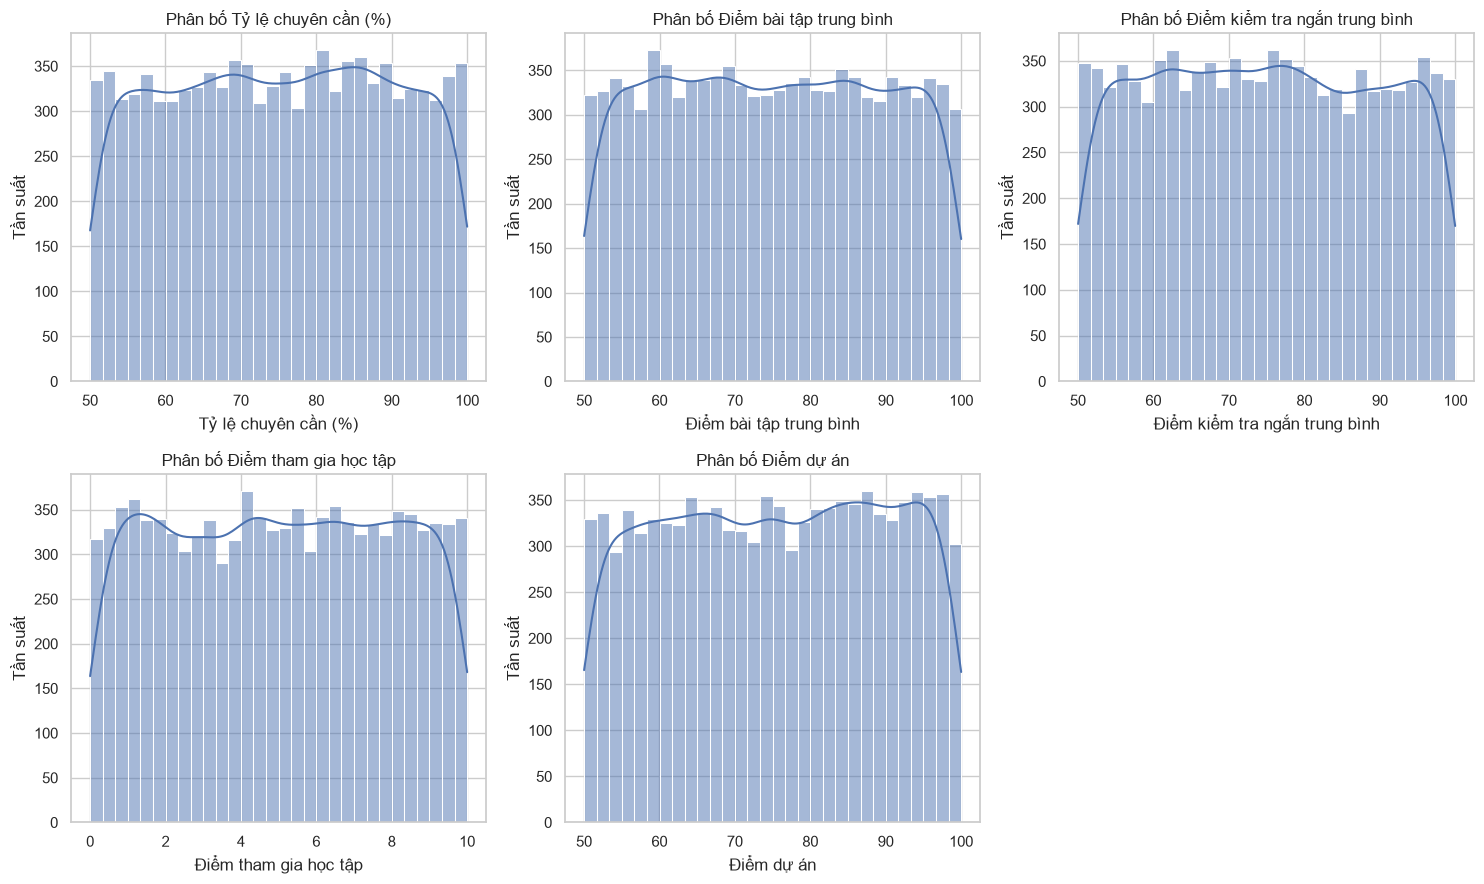

In [23]:

# 6.2. Phân bố các đặc trưng hành vi học tập

behavior_cols = [
    "Tỷ lệ chuyên cần (%)",
    "Điểm bài tập trung bình",
    "Điểm kiểm tra ngắn trung bình",
    "Điểm tham gia học tập",
    "Điểm dự án"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(behavior_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Phân bố {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Tần suất")

# Ẩn biểu đồ thứ 6 vì chỉ có 5 đặc trưng
axes[-1].axis("off")

plt.tight_layout()
plt.show()



### 6.3. Phát hiện giá trị ngoại lệ

Sử dụng Boxplot để quan sát phân bố và các giá trị có khả năng bất thường trong những thuộc tính hành vi học tập.

Các giá trị ngoại lệ sẽ được kiểm tra trước khi quyết định xử lý, không tự động xóa.


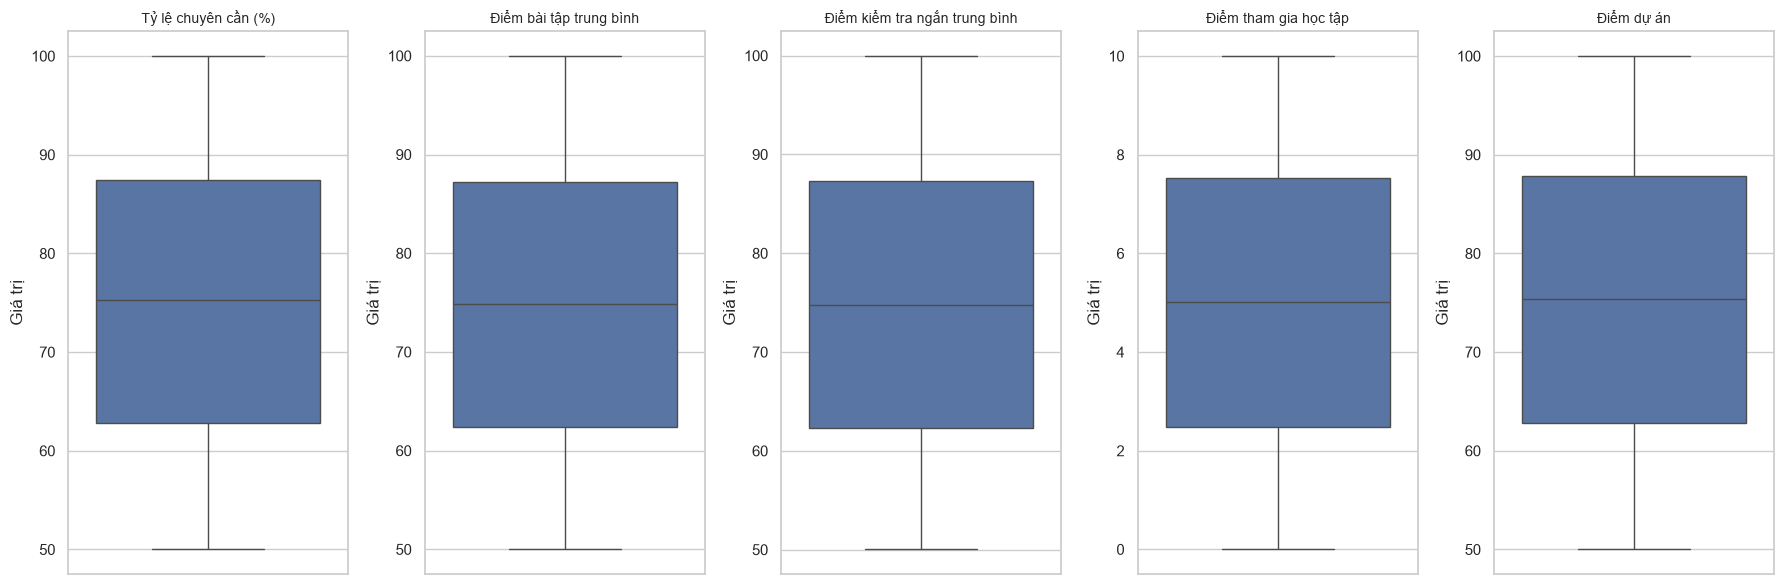

In [24]:

# 6.3. Phát hiện giá trị ngoại lệ

fig, axes = plt.subplots(1, 5, figsize=(18, 6))

for i, col in enumerate(behavior_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("Giá trị")

plt.tight_layout()
plt.show()



### 6.4. Phân tích tương quan giữa các đặc trưng

Sử dụng hệ số tương quan Pearson để đánh giá mối liên hệ tuyến tính giữa các thuộc tính hành vi học tập và kết quả học tập.

Mục đích:
- Phát hiện các thuộc tính có mức tương quan cao.
- Hỗ trợ lựa chọn đặc trưng cho K-Means.
- Tìm hiểu mối liên hệ giữa hành vi và kết quả học tập.


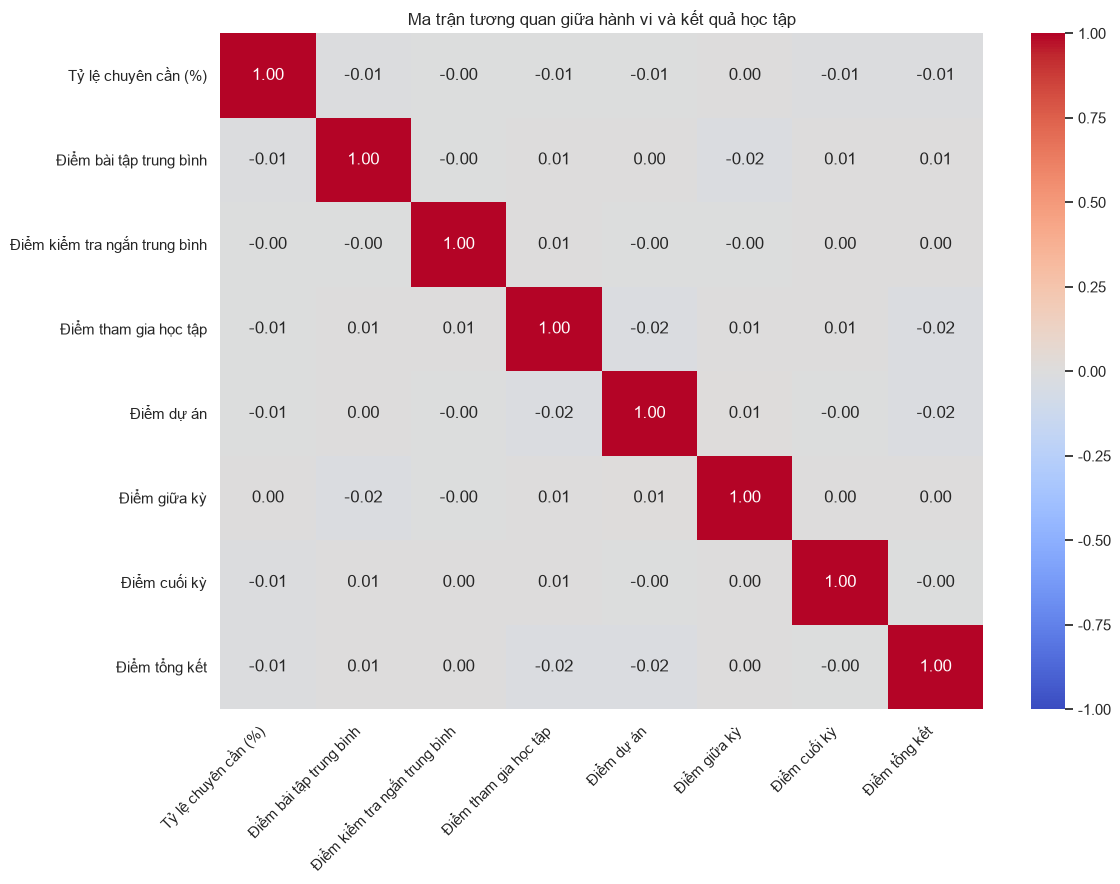

In [25]:

# 6.4. Phân tích tương quan giữa hành vi và kết quả học tập

corr_cols = behavior_cols + [
    "Điểm giữa kỳ",
    "Điểm cuối kỳ",
    "Điểm tổng kết"
]

# Tính hệ số tương quan Pearson
corr_matrix = df[corr_cols].corr(method="pearson")

# Vẽ ma trận tương quan
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Ma trận tương quan giữa hành vi và kết quả học tập")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



## 7. Đề xuất đặc trưng cho mô hình K-Means

Dựa trên mục tiêu phân nhóm sinh viên theo hành vi học tập, nhóm đề xuất sử dụng 5 thuộc tính:

1. **Tỷ lệ chuyên cần (%):** Phản ánh mức độ tham gia các buổi học.
2. **Điểm bài tập trung bình:** Phản ánh kết quả thực hiện bài tập.
3. **Điểm kiểm tra ngắn trung bình:** Phản ánh kết quả các bài kiểm tra thường xuyên.
4. **Điểm tham gia học tập:** Phản ánh mức độ tham gia hoạt động học tập.
5. **Điểm dự án:** Phản ánh kết quả thực hiện các dự án học tập.

### Các thuộc tính không sử dụng để phân cụm

- **Mã sinh viên, Họ, Tên:** Chỉ phục vụ định danh và tra cứu.
- **Giới tính, Tuổi, Ngành học:** Không đưa vào bộ đặc trưng phân cụm ban đầu.
- **Điểm giữa kỳ, Điểm cuối kỳ, Điểm tổng kết:** Giữ lại để phân tích kết quả học tập sau khi phân nhóm.
- **Điểm Toán, Điểm Đọc hiểu, Điểm Viết, Điểm Khoa học:** Giữ lại để phục vụ phân tích bổ sung.
- **Tham gia khóa ôn tập:** Có thể dùng để mô tả và so sánh các nhóm sinh viên sau phân cụm.

### Định hướng xây dựng mô hình

Bộ 5 đặc trưng trên là phương án đề xuất ban đầu, chưa phải kết quả lựa chọn đặc trưng cuối cùng.

Thành viên B sẽ tiếp tục:

- Kiểm tra mối tương quan giữa các đặc trưng.
- Chuẩn hóa dữ liệu bằng StandardScaler.
- Xác định số cụm phù hợp bằng Elbow và Silhouette Score.
- Huấn luyện và đánh giá mô hình K-Means.
- Phân tích đặc điểm từng cụm để hỗ trợ xây dựng các gợi ý học tập.

**Lưu ý:** Các thuộc tính được chọn chủ yếu là chỉ báo gián tiếp về hành vi học tập thông qua mức độ chuyên cần, tham gia và kết quả thực hiện hoạt động học tập.
